# The footprint model

09 fitted a record of events with footprints two ways and found that one term per event recovers the rate events start at. That likelihood says only that an event's center lies somewhere in the units it names. This notebook writes the whole generative story into the model: each event has a center and an elliptical footprint, the footprint touches units at the event's reporting level, and each touched unit is named with a probability. The center and the footprint's shape are summed out of every event's likelihood exactly, over the atoms and over a grid of shapes, so the model learns the rate, the distribution of footprint sizes and shapes, and the naming probability together, and from them the rate at which a footprint covers each atom.

In [20]:
import time

import arviz as az
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import shapely

from scipy.stats import norm
from tqdm.auto import tqdm

from nested_plotting import POSTERIOR_COLOR, TRUTH_COLOR, plot_atoms, plot_fields

from climate_risk.models.aggregation import Aggregation
from climate_risk.plotting import configure_plot_style

configure_plot_style()

# One generator per stage, so rerunning a stage never moves the draws of another. The first six match 07 and 09.
SEED = 20261020
GEOGRAPHY_SEED, COLOR_SEED, FIELD_SEED, EVENT_SEED, REPORTING_SEED, OFFSET_SEED, FOOTPRINT_SEED = (SEED + step for step in range(7))

## The geography and the truth

Both as in 07 and 09: a 30 by 30 lattice of atoms grouped into 60 ADM2, 12 ADM1 and 3 ADM0 units, and a log rate linear in two covariates plus a Matern 3/2 field and nested unit offsets, scaled to the median country's 25 climate-related events per country.

In [2]:
GRID_SIDE = 30
N_ADM2, N_ADM1, N_ADM0 = 60, 12, 3
LLOYD_STEPS = 25
LEVELS = ("ADM2", "ADM1", "ADM0")

n_atoms = GRID_SIDE**2
column, row = (index.ravel() for index in np.meshgrid(np.arange(GRID_SIDE), np.arange(GRID_SIDE)))
atom_x, atom_y = (column + 0.5) / GRID_SIDE, (row + 0.5) / GRID_SIDE
atom_centroids = np.column_stack([atom_x, atom_y])

# Edges as k / GRID_SIDE, computed once per grid line, so neighbors share them exactly and a
# dissolve leaves no slivers between atoms.
edges = np.arange(GRID_SIDE + 1) / GRID_SIDE
atom_cells = gpd.GeoSeries(shapely.box(edges[column], edges[row], edges[column + 1], edges[row + 1]))

In [3]:
def group_into(centroids, n_groups, *, weights, rng):
    """Assign each child to one of ``n_groups`` compact parents, by weighted Lloyd iteration."""
    seeds = centroids[rng.choice(len(centroids), size=n_groups, replace=False)]
    for _ in range(LLOYD_STEPS):
        parent = np.argmin(((centroids[:, None, :] - seeds[None, :, :]) ** 2).sum(axis=-1), axis=1)
        seeds = np.array(
            [np.average(centroids[parent == group], axis=0, weights=weights[parent == group]) for group in range(n_groups)]
        )

    return parent, seeds


geography_rng = np.random.default_rng(GEOGRAPHY_SEED)
adm2_of_atom, adm2_centroids = group_into(atom_centroids,
                                          N_ADM2,
                                          weights=np.ones(n_atoms),
                                          rng=geography_rng)
adm1_of_adm2, adm1_centroids = group_into(adm2_centroids,
                                          N_ADM1,
                                          weights=np.bincount(adm2_of_atom),
                                          rng=geography_rng)
adm0_of_adm1, _ = group_into(adm1_centroids,
                             N_ADM0,
                             weights=np.bincount(adm1_of_adm2[adm2_of_atom]),
                             rng=geography_rng)

unit_of_atom = {
    "ADM2": adm2_of_atom,
    "ADM1": adm1_of_adm2[adm2_of_atom],
    "ADM0": adm0_of_adm1[adm1_of_adm2[adm2_of_atom]],
}
borders = {
    level: gpd.GeoDataFrame({"unit": unit_of_atom[level]}, geometry=atom_cells).dissolve(by="unit").boundary
    for level in LEVELS
}
atoms_per_unit = {level: np.bincount(unit_of_atom[level]) for level in LEVELS}
n_units = {level: len(atoms_per_unit[level]) for level in LEVELS}

In [4]:
# Calibrated against EM-DAT in 07: the median country's climate-related events from 1990 to 2023, and the share of
# events at each finest reporting level.
REAL_EVENTS_PER_COUNTRY = 25.0
REAL_LEVEL_SHARES = {"ADM2": 0.43, "ADM1": 0.44, "ADM0": 0.12}

TARGET_EVENTS = round(N_ADM0 * REAL_EVENTS_PER_COUNTRY)
TRUE_SLOPES = np.array([-0.8, 0.5])
COVARIATE_NAMES = ("distance to river", "elevation")
TRUE_FIELD_AMPLITUDE = 0.7
TRUE_FIELD_LENGTHSCALE = 0.12
TRUE_OFFSET_SDS = {"ADM2": 0.3, "ADM1": 0.4, "ADM0": 0.5}
FIELD_JITTER = 1e-8


def standardized(values):
    """Centered and scaled to unit standard deviation."""
    return (values - values.mean()) / values.std()


def matern32(points, *, amplitude, lengthscale):
    """The Matern 3/2 covariance between every pair of ``points``."""
    scaled = np.sqrt(3.0) * np.sqrt(((points[:, None, :] - points[None, :, :]) ** 2).sum(axis=-1)) / lengthscale

    return amplitude**2 * (1.0 + scaled) * np.exp(-scaled)


river_x = 0.5 + 0.2 * np.sin(2.5 * np.pi * atom_y)
elevation = np.sin(3.0 * atom_x + 1.0) * np.cos(2.0 * atom_y) + 0.6 * atom_y
covariates = np.column_stack([standardized(np.abs(atom_x - river_x)), standardized(elevation)])

field_rng = np.random.default_rng(FIELD_SEED)
field_covariance = matern32(atom_centroids, amplitude=TRUE_FIELD_AMPLITUDE, lengthscale=TRUE_FIELD_LENGTHSCALE)
field_covariance[np.diag_indices(n_atoms)] += FIELD_JITTER
true_field = np.linalg.cholesky(field_covariance) @ field_rng.standard_normal(n_atoms)
true_field -= true_field.mean()

offset_rng = np.random.default_rng(OFFSET_SEED)
true_offsets = {
    level: offset_rng.normal(loc=0.0, scale=TRUE_OFFSET_SDS[level], size=len(atoms_per_unit[level])) for level in LEVELS
}
offset_part = sum(true_offsets[level][unit_of_atom[level]] for level in LEVELS)

linear_part = covariates @ TRUE_SLOPES
TRUE_INTERCEPT = float(np.log(TARGET_EVENTS) - np.log(np.exp(linear_part + true_field + offset_part).sum()))
true_log_rate = TRUE_INTERCEPT + linear_part + true_field + offset_part
true_rate = np.exp(true_log_rate)

## Elliptical footprints

An event falls at an atom drawn from the true rate. Its footprint is an ellipse centered there, described by an equal-area radius $r$, an aspect ratio $\rho$ and an angle: the semi-axes are $r / \sqrt{\rho}$ and $r \sqrt{\rho}$, so the area is $\pi r^2$ whatever the aspect. The aspect is 1, 0.5 or 0.25 and the angle is uniform. The footprint touches every unit at the event's reporting level that holds an atom whose centroid lies inside it, and the event names its own unit and each other touched unit with probability 0.7.

The radius is log-normal, calibrated to the share of its country a real event names. In 08, hydrometeorological events reported at ADM2 name a median 0.8% of their country's ADM2 units, 2.7% at the 75th percentile, 7.7% at the 90th and 46% at the 99th. Read as the footprint's share of the country's area, each quantile gives a radius on the simulated map, where a country is about a third of the area, and a log-normal fitted through the four sets the median and the spread. Named units cover more area than the footprint inside them, so this calibration errs large.

In [5]:
# Hydrometeorological events reported at ADM2 in 08: the share of the country's GADM ADM2 units named, by quantile.
REAL_SHARE_OF_COUNTRY = {0.5: 0.008, 0.75: 0.027, 0.9: 0.0768, 0.99: 0.4624}

country_area = np.bincount(unit_of_atom["ADM0"]).mean() / n_atoms
quantiles = np.array(list(REAL_SHARE_OF_COUNTRY))
radius_at_quantile = np.sqrt(np.array(list(REAL_SHARE_OF_COUNTRY.values())) * country_area / np.pi)
TRUE_RADIUS_SPREAD, log_median = np.polyfit(norm.ppf(quantiles), np.log(radius_at_quantile), deg=1)
TRUE_MEDIAN_RADIUS = float(np.exp(log_median))

pd.DataFrame({
    "real share of country": list(REAL_SHARE_OF_COUNTRY.values()),
    "radius on the map": radius_at_quantile,
    "fitted log-normal radius": TRUE_MEDIAN_RADIUS * np.exp(TRUE_RADIUS_SPREAD * norm.ppf(quantiles)),
}, index=pd.Index(quantiles, name="quantile")).round(4)

,real share of country,radius on the map,fitted log-normal radius
quantile,,,
0.50,0.01,0.03,0.03
0.75,0.03,0.05,0.05
0.90,0.08,0.09,0.09
0.99,0.46,0.22,0.22


In [6]:
LARGEST_RADIUS = 1.0
ASPECTS = (1.0, 0.5, 0.25)
TRUE_ASPECT_WEIGHTS = np.array([0.4, 0.4, 0.2])
TRUE_NAMING_PROBABILITY = 0.7
SCALES = (1, 10)
FOOTPRINT_REGIMES = ("ADM2", "mixed")

# Offsets from every atom (rows) to every other atom (columns).
offset_x = atom_x[None, :] - atom_x[:, None]
offset_y = atom_y[None, :] - atom_y[:, None]


def inside_ellipse(dx, dy, radius, aspect, angle):
    """Whether offsets ``dx`` and ``dy`` from a center lie inside the ellipse of equal-area ``radius``."""
    along = dx * np.cos(angle) + dy * np.sin(angle)
    across = -dx * np.sin(angle) + dy * np.cos(angle)

    return (along * np.sqrt(aspect) / radius) ** 2 + (across / (radius * np.sqrt(aspect))) ** 2 <= 1.0


def name_units(center, inside, level, rng):
    """The units at ``level`` an event names: its own, and each other one its footprint touches with the naming probability."""
    touched = np.unique(unit_of_atom[level][inside])
    own = unit_of_atom[level][center]

    return touched[(touched == own) | (rng.random(len(touched)) < TRUE_NAMING_PROBABILITY)]


def draw_levels(regime, n_events, rng):
    """Each event's reporting level under ``regime``."""
    if regime == "mixed":
        shares = np.array(list(REAL_LEVEL_SHARES.values()))
        return rng.choice(list(REAL_LEVEL_SHARES), size=n_events, p=shares / shares.sum())

    return np.full(n_events, regime)


event_rng = np.random.default_rng(EVENT_SEED)
footprint_rng = np.random.default_rng(FOOTPRINT_SEED + 1)
reporting_rng = np.random.default_rng(REPORTING_SEED)

records = {}
for scale in SCALES:
    centers = np.repeat(np.arange(n_atoms), event_rng.poisson(scale * true_rate))
    radii = np.minimum(TRUE_MEDIAN_RADIUS * np.exp(TRUE_RADIUS_SPREAD * footprint_rng.standard_normal(len(centers))), LARGEST_RADIUS)
    aspects = footprint_rng.choice(ASPECTS, size=len(centers), p=TRUE_ASPECT_WEIGHTS)
    angles = footprint_rng.uniform(0.0, np.pi, size=len(centers))
    insides = [inside_ellipse(offset_x[center], offset_y[center], radius, aspect, angle)
               for center, radius, aspect, angle in zip(centers, radii, aspects, angles)]

    for regime in FOOTPRINT_REGIMES:
        levels = draw_levels(regime, len(centers), reporting_rng)
        named = [name_units(center, inside, level, reporting_rng) for center, inside, level in zip(centers, insides, levels)]
        records[(scale, regime)] = {"centers": centers,
                                    "insides": insides,
                                    "levels": levels,
                                    "named": named,
                                    "units named": np.array([len(units) for units in named])}

pd.DataFrame({
    f"{regime}, x{scale}": {
        "events": len(record["units named"]),
        "units named per event, mean": record["units named"].mean(),
        "events naming one unit": (record["units named"] == 1).mean(),
        "units named, median": np.median(record["units named"]),
        "units named, 90%": np.quantile(record["units named"], 0.9),
        "ADM2 events, share of country, median": np.median(record["units named"][record["levels"] == "ADM2"]) / N_ADM2 * N_ADM0,
        "ADM2 events, share of country, 90%": np.quantile(record["units named"][record["levels"] == "ADM2"], 0.9) / N_ADM2 * N_ADM0,
    }
    for (scale, regime), record in records.items()
}).round(3)

,"ADM2, x1","mixed, x1","ADM2, x10","mixed, x10"
events,79.00,79.00,696.00,696.00
"units named per event, mean",1.95,1.39,1.85,1.56
events naming one unit,0.70,0.76,0.68,0.74
"units named, median",1.00,1.00,1.00,1.00
"units named, 90%",3.00,2.00,3.00,3.00
"ADM2 events, share of country, median",0.05,0.05,0.05,0.05
"ADM2 events, share of country, 90%",0.15,0.10,0.15,0.15


The fitted radius has a median of 0.029, a little under one atom, and a spread of 0.87, and it passes within rounding of all four quantile radii, so the real shares are close to log-normal. Most footprints now stay inside one ADM2 unit: 68% to 76% of events name a single unit, the median is one, and the 90th percentile is two or three units. A simulated country holds 20 ADM2 units, so one unit is already 5% of it and the median share sits on that floor, against a real 0.8%. At the 90th percentile ADM2 events name 15% of their country, against a real 7.7%.

## Summing out the center and the shape

The model's footprints come from a grid of shapes $k$: ten equal-area radii from 0.02 to 1.0 spaced evenly in the log, the three aspects, and four angles for the two elongated ones, 90 shapes in all. A shape's weight $w_k$ is the probability mass the log-normal radius distribution puts in its radius's bin, times its aspect's weight, divided by the number of angles it shares. For every center atom $c$ and shape $k$ the units touched at each level, $T_{ck}$, are computed once.

An event that names the set $S$ at its level could have come from any center $c$ whose own unit is in $S$ and any shape whose footprint at $c$ touches all of $S$. Each such pair produced the record with probability
$$\frac{\lambda_c}{\Lambda}\, w_k\, q^{|S| - 1} (1 - q)^{|T_{ck}| - |S|},$$
own unit named for certain, the rest of $S$ named and the other touched units missed, each with the naming probability $q$. The event's likelihood is the sum over those pairs, which is exact for the grid. Each event's pairs and the count of touched units it missed are found once, before sampling.

In [7]:
GRID_RADII = np.geomspace(0.02, LARGEST_RADIUS, 10)
GRID_ANGLES = np.arange(4) * np.pi / 4
# Interior bin edges halfway between neighboring radii in the log; the outer bins take the tails.
LOG_RADIUS_EDGES = (np.log(GRID_RADII[:-1]) + np.log(GRID_RADII[1:])) / 2

shapes = pd.DataFrame(
    [{"radius_index": radius_index, "aspect_index": aspect_index, "angle": angle, "angles_at_aspect": 1 if aspect == 1.0 else len(GRID_ANGLES)}
     for radius_index in range(len(GRID_RADII))
     for aspect_index, aspect in enumerate(ASPECTS)
     for angle in ([0.0] if aspect == 1.0 else GRID_ANGLES)]
)
shape_coverage = np.stack([
    inside_ellipse(offset_x, offset_y, GRID_RADII[shape.radius_index], ASPECTS[shape.aspect_index], shape.angle)
    for shape in shapes.itertuples()
])
touched_by_shape = {
    level: shape_coverage.astype(np.float32) @ np.eye(n_units[level], dtype=np.float32)[unit_of_atom[level]] > 0
    for level in LEVELS
}


def footprint_pairs(record):
    """Every (event, center, shape) that could have produced the record, with the count of touched units it missed."""
    events, centers, shape_indices, missed = [], [], [], []
    for event, (level, named) in enumerate(zip(record["levels"], record["named"], strict=True)):
        candidates = np.flatnonzero(np.isin(unit_of_atom[level], named))
        touched = touched_by_shape[level][:, candidates, :]
        shape_index, candidate_index = np.nonzero(touched[:, :, named].all(axis=-1))

        events.append(np.full(len(shape_index), event))
        centers.append(candidates[candidate_index])
        shape_indices.append(shape_index)
        missed.append(touched.sum(axis=-1)[shape_index, candidate_index] - len(named))

    events = np.concatenate(events)

    return {
        "event": events,
        "center": np.concatenate(centers),
        "shape": np.concatenate(shape_indices),
        "missed": np.concatenate(missed),
        "by event": Aggregation(units=tuple(f"event {event}" for event in range(len(record["named"]))),
                                rows=events,
                                columns=np.arange(len(events)),
                                weights=np.ones(len(events)),
                                n_cells=len(events)),
        "named": record["units named"],
    }


pairs = {key: footprint_pairs(record) for key, record in tqdm(records.items(), desc="compatible pairs")}

pd.DataFrame({
    f"{regime}, x{scale}": {
        "pairs": len(found["center"]),
        "pairs per event, median": np.median(np.bincount(found["event"])),
        "events with no pair": int((np.bincount(found["event"], minlength=len(found["named"])) == 0).sum()),
    }
    for (scale, regime), found in pairs.items()
})

compatible pairs:   0%|          | 0/4 [00:00<?, ?it/s]

,"ADM2, x1","mixed, x1","ADM2, x10","mixed, x10"
pairs,140569.00,445945.00,1225879.00,4767414.00
"pairs per event, median",1753.00,5400.00,1632.00,5400.00
events with no pair,0.00,0.00,0.00,0.00


Two exact groupings shrink the sum the sampler evaluates. An event's term depends only on its record, its level and the set it names, so events with the same record share one term, weighted by how many there are. Within a record, pairs with the same center and the same count of missed units differ only in their shape, so their shape weights add into one factor, $\sum_{k} w_k$ over those shapes, which is a sparse product with the weight vector. The terms left are one per record, center and missed count.

In [8]:
def group_records(key):
    """The pairs of each distinct record, grouped by center and missed count, with how many events share each record."""
    record, found = records[key], pairs[key]
    record_index = {}
    record_of_event = np.array([record_index.setdefault((level, tuple(np.sort(named))), len(record_index))
                                for level, named in zip(record["levels"], record["named"], strict=True)])
    first_event = np.array([np.flatnonzero(record_of_event == index)[0] for index in range(len(record_index))])

    kept = np.isin(found["event"], first_event)
    record_of_first = np.full(len(record_of_event), -1)
    record_of_first[first_event] = np.arange(len(first_event))
    terms, term_of_pair = np.unique(np.column_stack([record_of_first[found["event"][kept]], found["center"][kept], found["missed"][kept]]),
                                    axis=0,
                                    return_inverse=True)
    term_of_pair = term_of_pair.ravel()

    return {
        "multiplicity": np.bincount(record_of_event),
        "named": record["units named"][first_event],
        "center": terms[:, 1],
        "missed": terms[:, 2],
        "pairs kept": len(term_of_pair),
        "shape mass": Aggregation(units=tuple(f"term {term}" for term in range(len(terms))),
                                  rows=term_of_pair,
                                  columns=found["shape"][kept],
                                  weights=np.ones(len(term_of_pair)),
                                  n_cells=len(shapes)),
        "by record": Aggregation(units=tuple(f"record {index}" for index in range(len(first_event))),
                                 rows=terms[:, 0],
                                 columns=np.arange(len(terms)),
                                 weights=np.ones(len(terms)),
                                 n_cells=len(terms)),
    }


grouped = {key: group_records(key) for key in tqdm(records, desc="grouping")}

pd.DataFrame({
    f"{regime}, x{scale}": {
        "events": int(groups["multiplicity"].sum()),
        "distinct records": len(groups["multiplicity"]),
        "pairs": len(pairs[(scale, regime)]["center"]),
        "pairs of distinct records": groups["pairs kept"],
        "terms": len(groups["center"]),
    }
    for (scale, regime), groups in grouped.items()
})

grouping:   0%|          | 0/4 [00:00<?, ?it/s]

,"ADM2, x1","mixed, x1","ADM2, x10","mixed, x10"
events,79,79,696,696
distinct records,43,44,203,166
pairs,140569,445945,1225879,4767414
pairs of distinct records,79726,227930,417900,684061
terms,39639,41706,243514,196435


Every event has at least one compatible pair, so no record is impossible on the grid. The median ADM2 event has about 1,700 pairs, and the ten-times mixed record has 4.8 million in all, most of them large footprints whose missed units make them negligible. Grouping cuts that record to 166 distinct records and 196,000 terms.

## The models

Both models share 07's prior on the log rate. The event likelihood is 09's: the count of events, and each center somewhere in the units it names. The footprint model replaces each event's term with the grouped sum above, and adds priors on the footprint: a log-normal radius with its median's log Normal around log 0.1 with sd 1 and its spread HalfNormal(1), Dirichlet(1, 1, 1) weights on the three aspects, and a Beta(2, 2) naming probability. The count of events sharing each distinct record is observed through a `pm.CustomDist` whose log density is that count times the log of the record's summed probability. The check below confirms the grouped term equals the event-by-event sum.

In [9]:
HSGP_BOUNDARY_FACTOR = 4.0
HSGP_BASIS_PER_AXIS = 50
OFFSET_SD_PRIOR = 0.5
sample_kwargs = {
    "chains": 8,
    "cores": 8,
    "tune": 500,
    "draws": 250,
    "target_accept": 0.9,
    "nuts_sampler": "nutpie",
    "random_seed": SEED,
}
COORDS = {
    "covariate": COVARIATE_NAMES,
    "atom": np.arange(n_atoms),
    "aspect": [f"{aspect:g}" for aspect in ASPECTS],
    **{level: np.arange(n_units[level]) for level in LEVELS},
}


def latent_log_rate():
    """The log rate at every atom under 07's prior, built inside the current model."""
    intercept = pm.Normal("intercept",
                          mu=0.0,
                          sigma=2.0)
    slopes = pm.Normal("slopes",
                       mu=0.0,
                       sigma=1.0,
                       dims="covariate")

    # Mode at 0.1 of the domain, about the side of an ADM2 unit, with a tail out past an ADM0.
    field_lengthscale = pm.InverseGamma("field_lengthscale",
                                        alpha=3.0,
                                        beta=0.4)
    field_amplitude = pm.HalfNormal("field_amplitude", sigma=1.0)
    gp = pm.gp.HSGP(m=[HSGP_BASIS_PER_AXIS, HSGP_BASIS_PER_AXIS],
                    c=HSGP_BOUNDARY_FACTOR,
                    cov_func=field_amplitude**2 * pm.gp.cov.Matern32(input_dim=2, ls=field_lengthscale))
    field = gp.prior("field", X=atom_centroids, dims="atom")

    # Summing every level's offsets at the atom nests them: an ADM2's total is its ADM1's plus its own deviation.
    offset_part = 0.0
    for level in LEVELS:
        offset_sd = pm.HalfNormal(f"{level}_offset_sd", sigma=OFFSET_SD_PRIOR)
        standard = pm.Normal(f"{level}_offset_standard",
                             mu=0.0,
                             sigma=1.0,
                             dims=level)
        offsets = pm.Deterministic(f"{level}_offset", offset_sd * standard, dims=level)
        offset_part = offset_part + offsets[unit_of_atom[level]]

    return pm.Deterministic("log_rate",
                            intercept + pm.math.dot(covariates, slopes) + field + offset_part,
                            dims="atom")


def located_logp(value, probability):
    """Log probability of one event's record, given its probability under the model."""
    return pt.log(probability)


def counted_logp(count, probability):
    """Log probability of ``count`` events sharing one record, given the record's probability under the model."""
    return count * pt.log(probability)


def radius_mass(log_median_radius, radius_spread):
    """The log-normal radius distribution's probability in each grid radius's bin."""
    below = 0.5 * (1.0 + pt.erf((LOG_RADIUS_EDGES - log_median_radius) / (radius_spread * np.sqrt(2.0))))

    return pt.diff(pt.concatenate([pt.zeros(1), below, pt.ones(1)]))


def shape_weights(radius_masses, aspect_weights):
    """Each grid shape's probability: its radius bin's mass, times its aspect's weight, shared among its angles."""
    return (radius_masses[shapes["radius_index"].to_numpy()]
            * aspect_weights[shapes["aspect_index"].to_numpy()]
            / shapes["angles_at_aspect"].to_numpy())


def union_operator(record):
    """One row per event over the atoms of the units it names."""
    union_atoms = [np.flatnonzero(np.isin(unit_of_atom[level], named)) for level, named in zip(record["levels"], record["named"], strict=True)]

    return Aggregation(units=tuple(f"event {event}" for event in range(len(union_atoms))),
                       rows=np.repeat(np.arange(len(union_atoms)), [len(atoms) for atoms in union_atoms]),
                       columns=np.concatenate(union_atoms),
                       weights=np.ones(sum(len(atoms) for atoms in union_atoms)),
                       n_cells=n_atoms)


def build_event_model(key):
    """09's likelihood: a Poisson count of events, and each center somewhere in the units the event names."""
    unions = union_operator(records[key])

    with pm.Model(coords=COORDS | {"event": unions.units}) as model:
        rate = pm.math.exp(latent_log_rate())
        total_rate = rate.sum()
        pm.Poisson("event_count",
                   mu=total_rate,
                   observed=unions.n_units)
        pm.CustomDist("event_record",
                      unions.aggregate_symbolic(rate) / total_rate,
                      logp=located_logp,
                      observed=np.zeros(unions.n_units),
                      dims="event")

    return model


def build_footprint_model(key):
    """Each distinct record's probability summed over every center and grid shape that could have produced it."""
    groups = grouped[key]

    with pm.Model(coords=COORDS | {"record": groups["by record"].units}) as model:
        rate = pm.math.exp(latent_log_rate())

        log_median_radius = pm.Normal("log_median_radius",
                                      mu=np.log(0.1),
                                      sigma=1.0)
        radius_spread = pm.HalfNormal("radius_spread", sigma=1.0)
        aspect_weights = pm.Dirichlet("aspect_weights",
                                      a=np.ones(len(ASPECTS)),
                                      dims="aspect")
        naming_probability = pm.Beta("naming_probability",
                                     alpha=2.0,
                                     beta=2.0)
        weights = pm.Deterministic("shape_weight", shape_weights(radius_mass(log_median_radius, radius_spread), aspect_weights))

        term = rate[groups["center"]] * groups["shape mass"].aggregate_symbolic(weights) * (1.0 - naming_probability) ** groups["missed"]
        total_rate = rate.sum()
        pm.Poisson("event_count",
                   mu=total_rate,
                   observed=groups["multiplicity"].sum())
        pm.CustomDist("record_count",
                      groups["by record"].aggregate_symbolic(term) / total_rate * naming_probability ** (groups["named"] - 1),
                      logp=counted_logp,
                      observed=groups["multiplicity"],
                      dims="record")

    return model


BUILDERS = {"event likelihood": build_event_model, "footprint model": build_footprint_model}

In [11]:
def ungrouped_log_likelihood(key, rate, weights, naming_probability):
    """The record term summed event by event over every compatible pair, before any grouping."""
    found = pairs[key]
    terms = rate[found["center"]] * weights[found["shape"]] * (1.0 - naming_probability) ** found["missed"]
    per_event = np.bincount(found["event"], weights=terms, minlength=len(found["named"]))

    return float(np.sum(np.log(per_event / rate.sum()) + (found["named"] - 1) * np.log(naming_probability)))


checks = {}
for key in records:
    model = build_footprint_model(key)
    point = model.initial_point(random_seed=SEED)
    outputs = model.replace_rvs_by_values([model["log_rate"], model["shape_weight"], model["naming_probability"]])
    log_rate, weights, naming_probability = model.compile_fn(outputs, inputs=model.value_vars, on_unused_input="ignore")(point)

    checks[f"{key[1]}, x{key[0]}"] = {
        "ungrouped": ungrouped_log_likelihood(key, np.exp(log_rate), weights, naming_probability),
        "grouped": float(model.compile_logp(vars=[model["record_count"]])(point)),
    }

pd.DataFrame(checks).T.assign(difference=lambda table: table["grouped"] - table["ungrouped"])

,ungrouped,grouped,difference
"ADM2, x1",-497.42,-497.42,0.00
"mixed, x1",-357.43,-357.43,-0.00
"ADM2, x10",-4481.61,-4481.61,0.00
"mixed, x10",-3227.94,-3227.94,-0.00


In [12]:
fits = {}
for regime in FOOTPRINT_REGIMES:
    for model_name, build in BUILDERS.items():
        with build((1, regime)):
            fits[(1, regime, model_name)] = pm.sample(**sample_kwargs)

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard, log_median_radius, radius_spread, aspect_weights, naming_probability]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard, log_median_radius, radius_spread, aspect_weights, naming_probability]


Output()

In [13]:
for model_name, build in BUILDERS.items():
    with build((10, "ADM2")):
        fits[(10, "ADM2", model_name)] = pm.sample(**sample_kwargs)

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard, log_median_radius, radius_spread, aspect_weights, naming_probability]


Output()

In [14]:
for model_name, build in BUILDERS.items():
    with build((10, "mixed")):
        fits[(10, "mixed", model_name)] = pm.sample(**sample_kwargs)

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard, log_median_radius, radius_spread, aspect_weights, naming_probability]


Output()

## Sampling cost

The footprint model's trees are as deep as the event likelihood's, so its posterior is no harder to explore. What it costs is gradient time, which grows with the number of grouped terms: the footprint fits take 2.5 to 7.5 times as long as the event likelihood's, six minutes at most.

In [15]:
pd.DataFrame({
    f"{regime}, x{scale}, {model_name}": {
        "tree depth, mean": float(idata.sample_stats["depth"].mean()),
        "leapfrog steps per draw": float(idata.sample_stats["n_steps"].mean()),
        "step size": float(idata.sample_stats["step_size"].mean()),
        "divergences": int(idata.sample_stats["diverging"].sum()),
        "sampling seconds": float(idata.posterior.attrs["sampling_time"]),
    }
    for (scale, regime, model_name), idata in fits.items()
}).T.round(2)

,"tree depth, mean",leapfrog steps per draw,step size,divergences,sampling seconds
"ADM2, x1, event likelihood",5.00,30.98,0.14,2.00,19.71
"ADM2, x1, footprint model",5.00,31.00,0.15,0.00,49.97
"mixed, x1, event likelihood",5.00,31.00,0.14,1.00,30.22
"mixed, x1, footprint model",4.99,30.90,0.15,10.00,89.35
"ADM2, x10, event likelihood",5.63,52.43,0.10,31.00,41.79
"ADM2, x10, footprint model",5.65,52.19,0.10,1.00,280.38
"mixed, x10, event likelihood",5.75,55.48,0.10,4.00,47.35
"mixed, x10, footprint model",5.75,55.35,0.10,8.00,354.80


## What each model recovers

Both models against the center rate, the rate events start at. The footprint model also learns the footprint, so its posterior gives the hit rate, the rate a footprint covers each atom, $\sum_c \lambda_c \sum_k w_k\, 1[\text{atom inside shape } k \text{ at } c]$, computed here from 50 posterior draws. The true hit rate averages 2,000 footprints drawn from the true distribution.

In [16]:
INTERVAL = 0.9
INTERVAL_BOUNDS = ((1 - INTERVAL) / 2, (1 + INTERVAL) / 2)
TRUE_HIT_DRAWS = 2_000
HIT_RATE_DRAWS = 50

truth_rng = np.random.default_rng(FOOTPRINT_SEED + 2)
true_cover = np.zeros((n_atoms, n_atoms))
for radius, aspect, angle in zip(np.minimum(TRUE_MEDIAN_RADIUS * np.exp(TRUE_RADIUS_SPREAD * truth_rng.standard_normal(TRUE_HIT_DRAWS)), LARGEST_RADIUS),
                                 truth_rng.choice(ASPECTS, size=TRUE_HIT_DRAWS, p=TRUE_ASPECT_WEIGHTS),
                                 truth_rng.uniform(0.0, np.pi, size=TRUE_HIT_DRAWS)):
    true_cover += inside_ellipse(offset_x, offset_y, radius, aspect, angle)
true_hit_rate = true_rate @ (true_cover / TRUE_HIT_DRAWS)


def correlation(left, right):
    """Pearson correlation of two arrays."""
    return float(np.corrcoef(left, right)[0, 1])


def posterior_hit_rate(posterior):
    """Posterior mean hit rate over the draws of a stacked posterior."""
    rate = np.exp(posterior["log_rate"].to_numpy())
    weights = posterior["shape_weight"].to_numpy()

    return np.mean([rate[:, draw] @ np.tensordot(weights[:, draw], shape_coverage, axes=1) for draw in range(rate.shape[1])], axis=0)


def fit_summary(idata, scale):
    """How one fit's atom rates and field compare with the truth, and its footprint where it has one."""
    posterior = idata.posterior
    log_center_rate = np.log(scale * true_rate)
    log_rate = posterior["log_rate"].mean(dim=("chain", "draw")).to_numpy()
    lower, upper = posterior["log_rate"].quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()
    slopes = posterior["slopes"].mean(dim=("chain", "draw")).to_numpy()

    summary = {
        "total rate / true centers": float(np.exp(posterior["log_rate"]).sum("atom").mean() / (scale * true_rate.sum())),
        "log rate, correlation with center rate": correlation(log_rate, log_center_rate),
        f"center log rate, {INTERVAL:.0%} coverage": float(((log_center_rate >= lower) & (log_center_rate <= upper)).mean()),
        "field, correlation with truth": correlation(posterior["field"].mean(dim=("chain", "draw")).to_numpy(), true_field),
        **{f"slope on {name}": float(slope) for name, slope in zip(COVARIATE_NAMES, slopes, strict=True)},
    }
    if "naming_probability" not in posterior:
        return summary

    hit_rate = posterior_hit_rate(az.extract(idata, num_samples=HIT_RATE_DRAWS, random_seed=SEED))
    return summary | {
        "log hit rate, correlation with true hit rate": correlation(np.log(hit_rate), np.log(scale * true_hit_rate)),
        "hit rate total / true": float(hit_rate.sum() / (scale * true_hit_rate.sum())),
        "median radius": float(np.exp(posterior["log_median_radius"]).mean()),
        "radius spread": float(posterior["radius_spread"].mean()),
        **{f"aspect {aspect} weight": float(weight) for aspect, weight in zip(COORDS["aspect"], posterior["aspect_weights"].mean(dim=("chain", "draw")).to_numpy(), strict=True)},
        "naming probability": float(posterior["naming_probability"].mean()),
    }


truth_column = {
    "median radius": TRUE_MEDIAN_RADIUS,
    "radius spread": TRUE_RADIUS_SPREAD,
    **{f"aspect {aspect} weight": weight for aspect, weight in zip(COORDS["aspect"], TRUE_ASPECT_WEIGHTS, strict=True)},
    "naming probability": TRUE_NAMING_PROBABILITY,
    **{f"slope on {name}": slope for name, slope in zip(COVARIATE_NAMES, TRUE_SLOPES, strict=True)},
}
pd.DataFrame(
    {"truth": truth_column}
    | {f"{regime}, x{scale}, {model_name.split()[0]}": fit_summary(idata, scale) for (scale, regime, model_name), idata in fits.items()}
).round(2)

,truth,"ADM2, x1, event","ADM2, x1, footprint","mixed, x1, event","mixed, x1, footprint","ADM2, x10, event","ADM2, x10, footprint","mixed, x10, event","mixed, x10, footprint"
median radius,0.03,NaN,0.02,NaN,0.03,NaN,0.03,NaN,0.03
radius spread,0.87,NaN,1.07,NaN,1.13,NaN,0.97,NaN,0.94
aspect 1 weight,0.40,NaN,0.43,NaN,0.41,NaN,0.35,NaN,0.33
aspect 0.5 weight,0.40,NaN,0.28,NaN,0.33,NaN,0.51,NaN,0.44
aspect 0.25 weight,0.20,NaN,0.29,NaN,0.26,NaN,0.14,NaN,0.23
naming probability,0.70,NaN,0.71,NaN,0.60,NaN,0.56,NaN,0.65
slope on distance to river,-0.80,-0.46,-0.41,-0.38,-0.32,-0.61,-0.59,-0.53,-0.47
slope on elevation,0.50,0.80,0.68,0.88,0.83,0.63,0.56,0.64,0.67
total rate / true centers,NaN,1.06,1.06,1.06,1.07,0.93,0.93,0.93,0.93
"log rate, correlation with center rate",NaN,0.89,0.89,0.87,0.87,0.95,0.96,0.94,0.94


The footprint model recovers the footprint's typical size and the naming probability, and overstates its tail. The median radius comes back at 0.02 to 0.03 against 0.029 and the naming probability at 0.56 to 0.71 against 0.7, but the spread comes back at 0.94 to 1.13 against 0.87. A wider spread fattens the tail of large footprints, and since a footprint's hits grow with its area, the hit rate's total comes out 12% to 87% high, worst in the mixed record at 79 events. Its pattern still correlates with the true hit rate at 0.96 to 0.99 in log. The aspect weights are noisy at both event counts.

On the center rate the two models agree closely. Totals are within 7% of the truth, coverage is 91% to 94%, and correlations match to within 0.01. At 696 events the field correlation is 0.77 against 0.74 in the ADM2 record and 0.71 against 0.70 in the mixed one. Both models flatten the river slope, -0.47 to -0.61 against -0.8, and steepen the elevation slope, 0.56 to 0.67 at 696 events against 0.5.

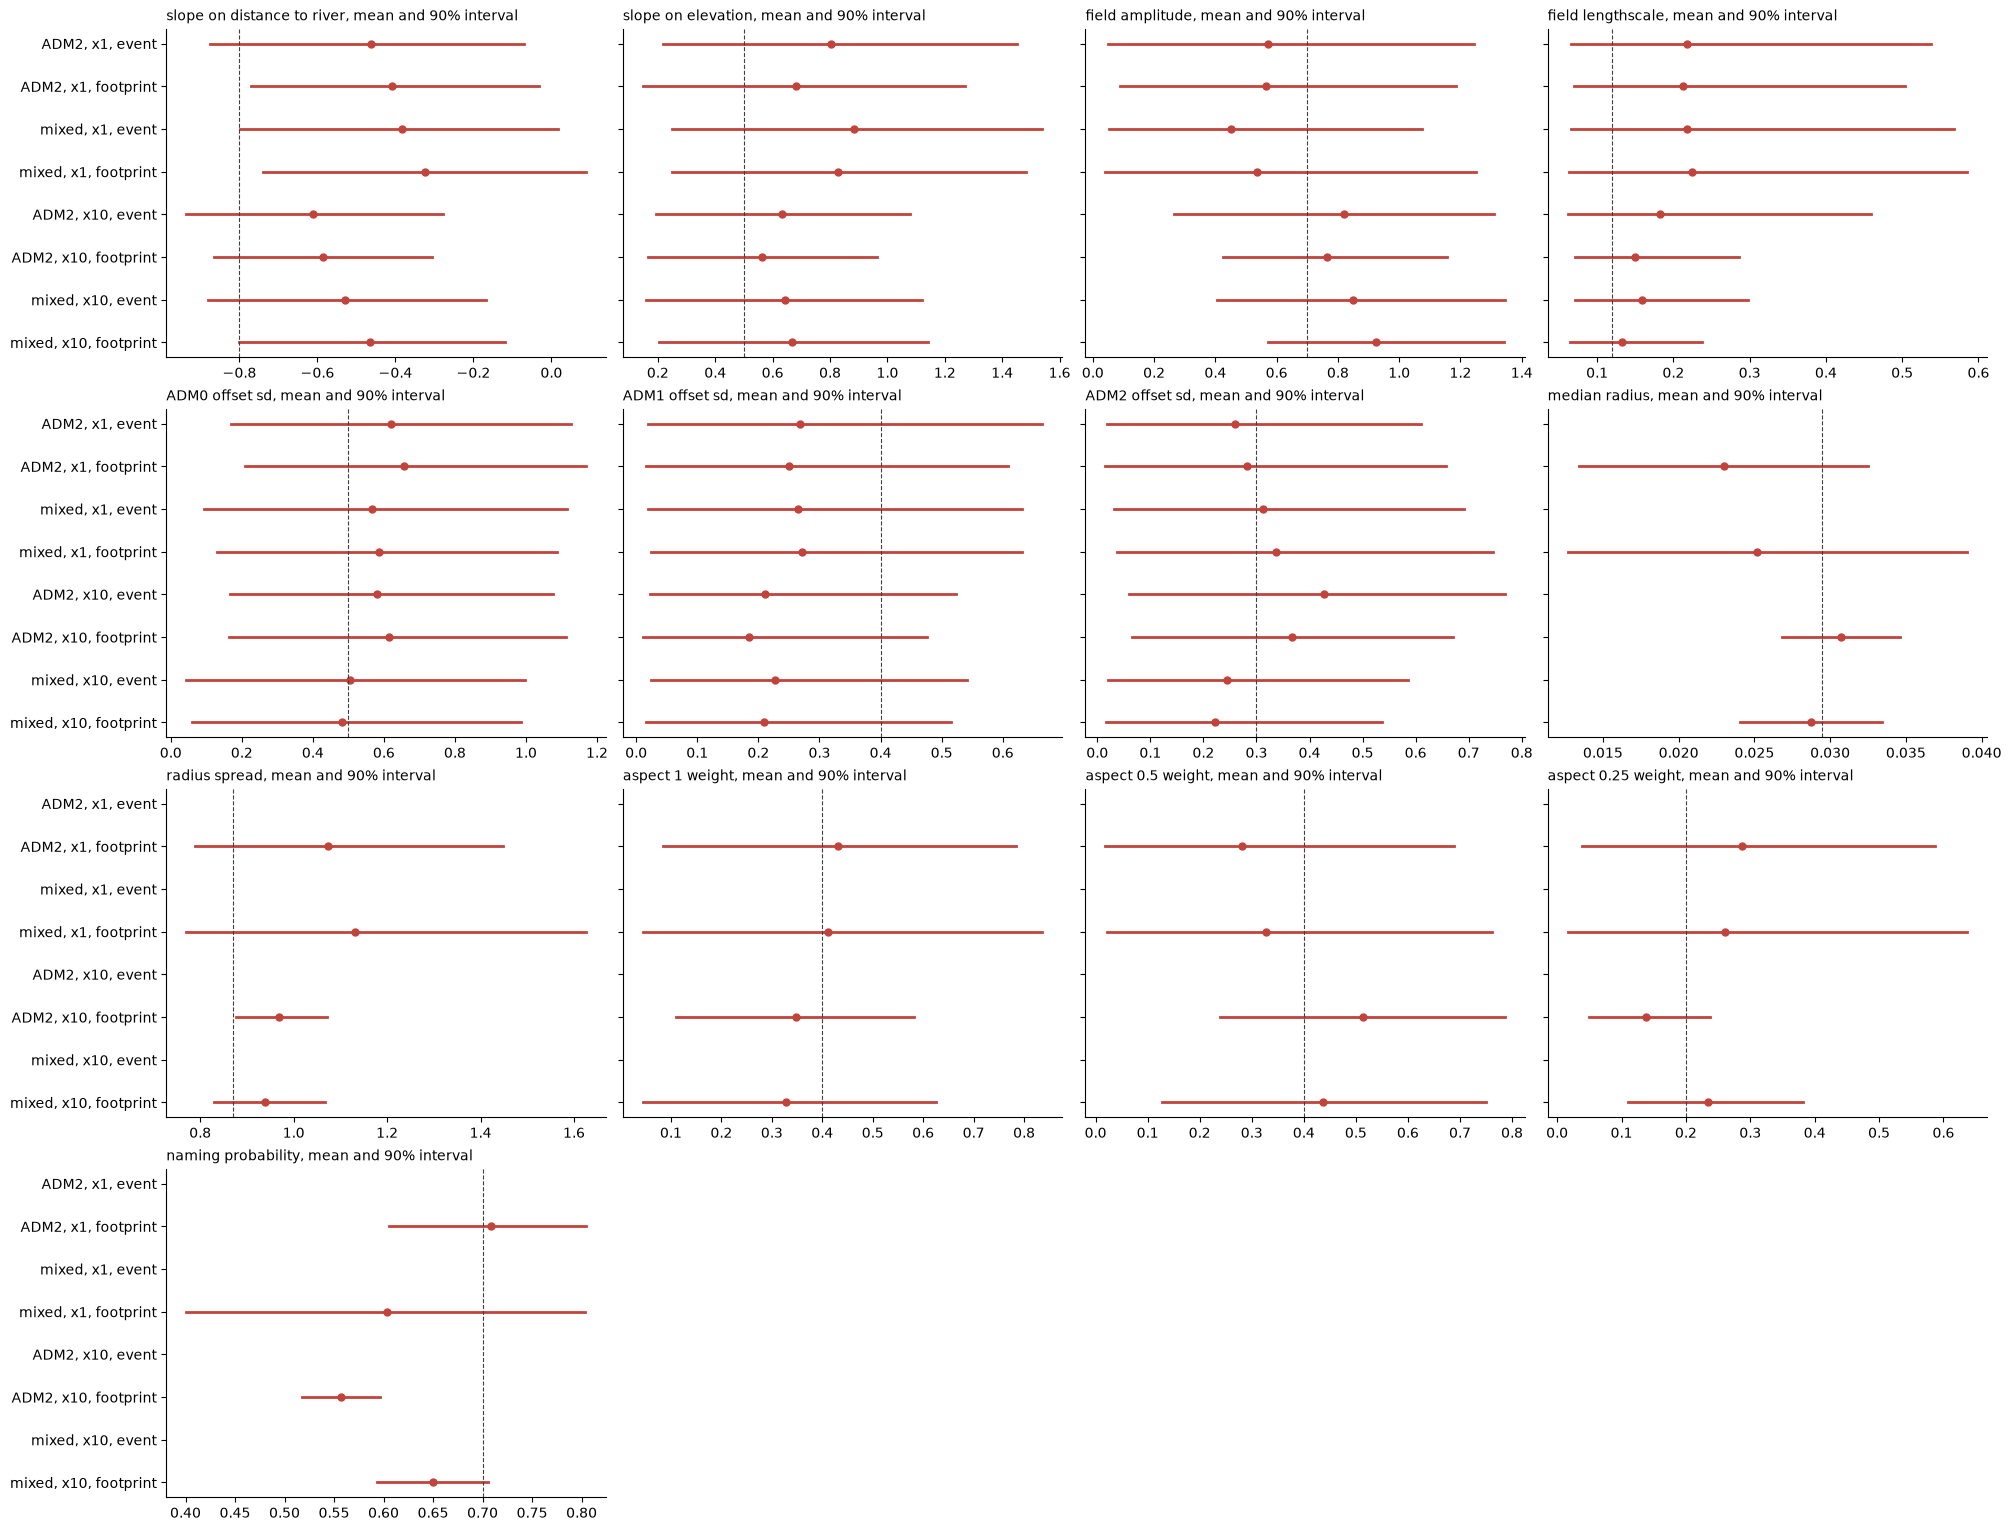

In [21]:
INTERVAL_PANEL_COLUMNS = 4


def parameter_draws(posterior):
    """Draws of every parameter with a known true value that the fit has, keyed by name."""
    draws = {
        **{f"slope on {name}": posterior["slopes"].sel(covariate=name) for name in COVARIATE_NAMES},
        "field amplitude": posterior["field_amplitude"],
        "field lengthscale": posterior["field_lengthscale"],
        **{f"{level} offset sd": posterior[f"{level}_offset_sd"] for level in reversed(LEVELS)},
    }
    if "naming_probability" not in posterior:
        return draws

    return draws | {
        "median radius": np.exp(posterior["log_median_radius"]),
        "radius spread": posterior["radius_spread"],
        **{f"aspect {aspect} weight": posterior["aspect_weights"].sel(aspect=aspect) for aspect in COORDS["aspect"]},
        "naming probability": posterior["naming_probability"],
    }


TRUE_PARAMETERS = {
    **{f"slope on {name}": slope for name, slope in zip(COVARIATE_NAMES, TRUE_SLOPES, strict=True)},
    "field amplitude": TRUE_FIELD_AMPLITUDE,
    "field lengthscale": TRUE_FIELD_LENGTHSCALE,
    **{f"{level} offset sd": TRUE_OFFSET_SDS[level] for level in reversed(LEVELS)},
    "median radius": TRUE_MEDIAN_RADIUS,
    "radius spread": TRUE_RADIUS_SPREAD,
    **{f"aspect {aspect} weight": weight for aspect, weight in zip(COORDS["aspect"], TRUE_ASPECT_WEIGHTS, strict=True)},
    "naming probability": TRUE_NAMING_PROBABILITY,
}
fit_labels = [f"{regime}, x{scale}, {model_name.split()[0]}" for scale, regime, model_name in fits]
fit_draws = [parameter_draws(idata.posterior) for idata in fits.values()]

n_rows = -(-len(TRUE_PARAMETERS) // INTERVAL_PANEL_COLUMNS)
figure, axes = plt.subplots(n_rows, INTERVAL_PANEL_COLUMNS, figsize=(5.0 * INTERVAL_PANEL_COLUMNS, 3.8 * n_rows), sharey=True)

for axis, (name, truth) in zip(axes.ravel(), TRUE_PARAMETERS.items()):
    for position, draws in enumerate(fit_draws):
        if name not in draws:
            continue
        lower, upper = draws[name].quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()
        axis.plot([lower, upper],
                  [position, position],
                  color=POSTERIOR_COLOR,
                  linewidth=2.0)
        axis.plot(float(draws[name].mean()),
                  position,
                  "o",
                  color=POSTERIOR_COLOR,
                  markersize=5)
    axis.axvline(truth,
                 color=TRUTH_COLOR,
                 linestyle="--",
                 linewidth=0.8)
    axis.set_title(f"{name}, mean and {INTERVAL:.0%} interval", loc="left", fontsize=10)

for axis in axes.ravel()[len(TRUE_PARAMETERS):]:
    axis.remove()
for row in axes:
    row[0].set_yticks(range(len(fit_labels)), fit_labels)
axes[0, 0].invert_yaxis()
plt.show()

Every rate parameter's 90% interval covers the truth at 696 events, and the footprint model narrows the field lengthscale's interval onto the true 0.12, 0.07 to 0.29 in the ADM2 record against 0.06 to 0.46 for the event likelihood. At 79 events the river slope's intervals end just short of -0.8 in two fits, and the offset sds stay at their prior, as in 07. The footprint's median radius is tight around the truth at 696 events, 0.027 to 0.035 in the ADM2 record, and the aspect weights cover theirs at both event counts. The spread and the naming probability trade off: in the ten-times ADM2 record the spread's interval, 0.88 to 1.07, sits just above the true 0.87, and the naming probability's, 0.52 to 0.60, below the true 0.7. Larger footprints whose touched units are more often missed reproduce the same records, and the mixed record, whose ADM1 and ADM0 events constrain both less, covers both truths.

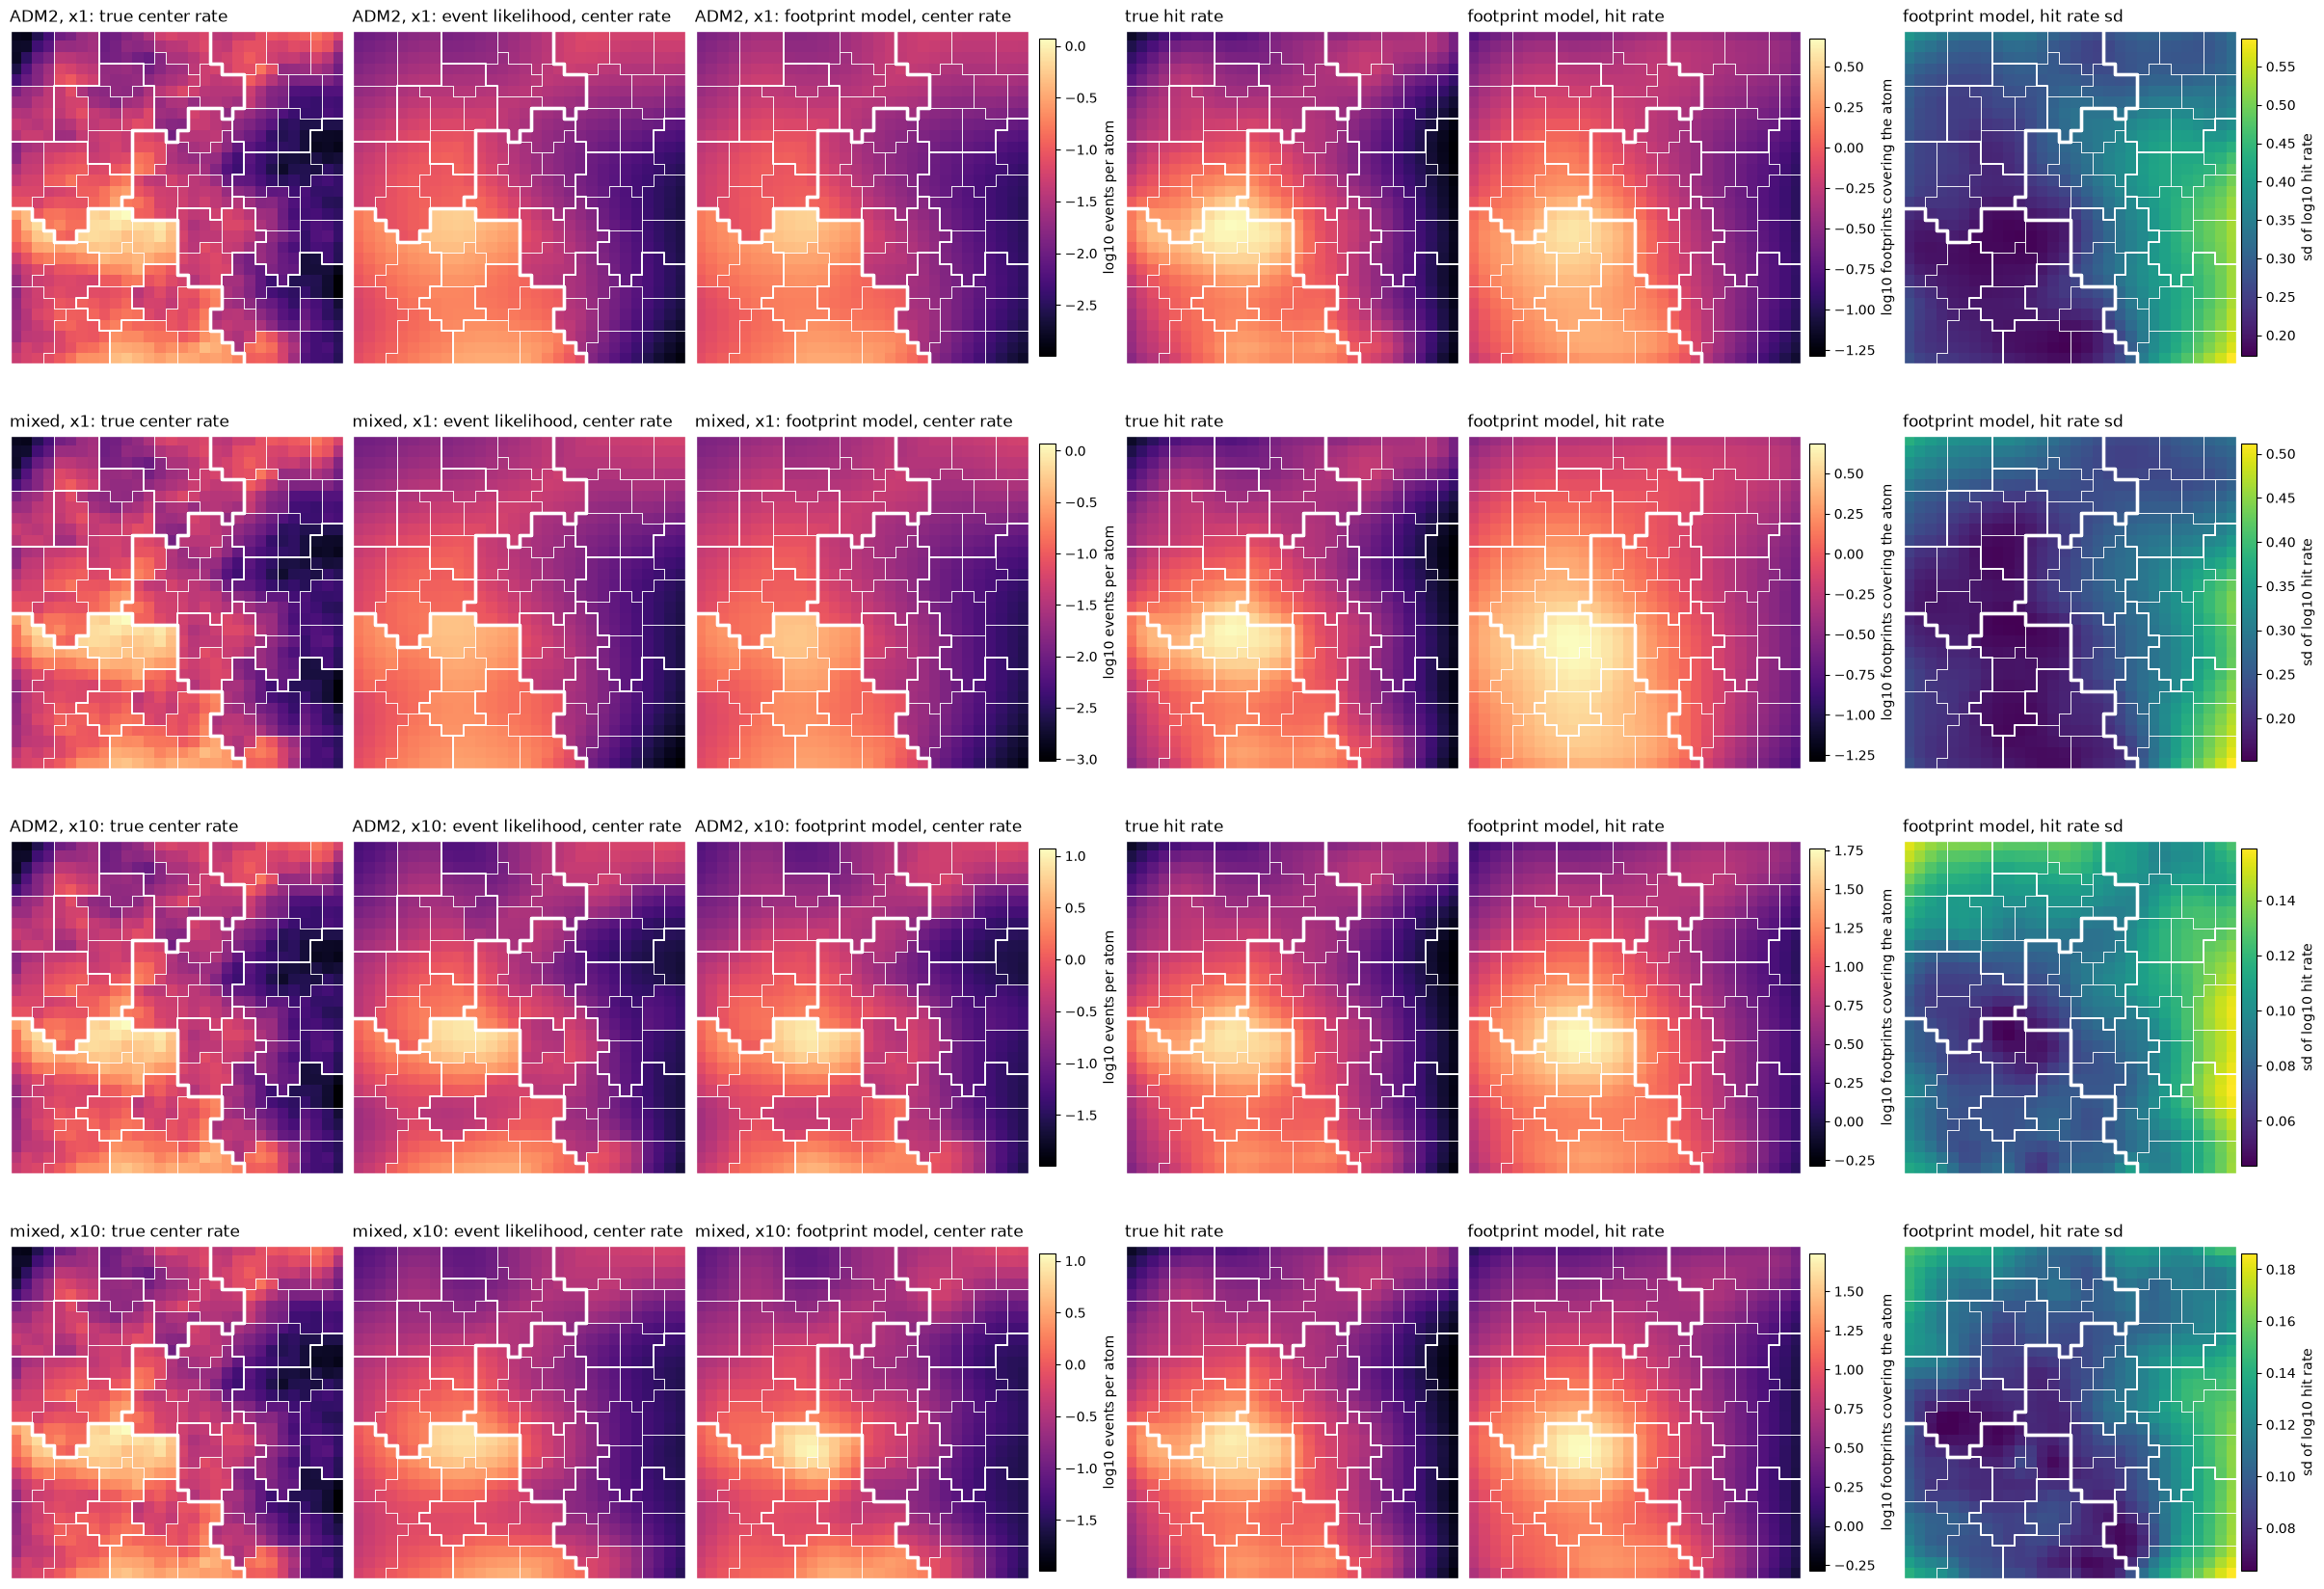

In [17]:
def hit_rate_draws(posterior):
    """The hit rate at every atom for each draw of a stacked posterior, shape ``(draw, atom)``."""
    rate = np.exp(posterior["log_rate"].to_numpy())
    weights = posterior["shape_weight"].to_numpy()

    return np.stack([rate[:, draw] @ np.tensordot(weights[:, draw], shape_coverage, axes=1) for draw in range(rate.shape[1])])


figure, axes = plt.subplots(len(records), 6, figsize=(24, 4.2 * len(records)))
for row_axes, (scale, regime) in zip(axes, records, strict=True):
    hits = hit_rate_draws(az.extract(fits[(scale, regime, "footprint model")], num_samples=HIT_RATE_DRAWS, random_seed=SEED))
    log_hits = np.log10(hits)
    center_maps = {
        "true center rate": np.log10(scale * true_rate),
        "event likelihood, center rate": fits[(scale, regime, "event likelihood")].posterior["log_rate"].mean(dim=("chain", "draw")).to_numpy() / np.log(10),
        "footprint model, center rate": fits[(scale, regime, "footprint model")].posterior["log_rate"].mean(dim=("chain", "draw")).to_numpy() / np.log(10),
    }
    hit_maps = {
        "true hit rate": np.log10(scale * true_hit_rate),
        "footprint model, hit rate": log_hits.mean(axis=0),
    }
    center_limits = (min(values.min() for values in center_maps.values()), max(values.max() for values in center_maps.values()))
    hit_limits = (min(values.min() for values in hit_maps.values()), max(values.max() for values in hit_maps.values()))

    for axis, (title, values) in zip(row_axes[:3], center_maps.items(), strict=True):
        drawn = plot_atoms(axis,
                           values,
                           borders,
                           title=f"{regime}, x{scale}: {title}",
                           vmin=center_limits[0],
                           vmax=center_limits[1])
    figure.colorbar(drawn, ax=row_axes[:3], shrink=0.8, pad=0.01, label="log10 events per atom")

    for axis, (title, values) in zip(row_axes[3:5], hit_maps.items(), strict=True):
        drawn = plot_atoms(axis,
                           values,
                           borders,
                           title=title,
                           vmin=hit_limits[0],
                           vmax=hit_limits[1])
    figure.colorbar(drawn, ax=row_axes[3:5], shrink=0.8, pad=0.01, label="log10 footprints covering the atom")

    drawn = plot_atoms(row_axes[5],
                       log_hits.std(axis=0),
                       borders,
                       title="footprint model, hit rate sd",
                       cmap="viridis")
    figure.colorbar(drawn, ax=row_axes[5], shrink=0.8, pad=0.01, label="sd of log10 hit rate")

plt.show()

Across the whole map, the two models' center rates are close to indistinguishable. At 79 events both draw the broad southwestern hotspot and the cold east and smooth over everything finer. At 696 events both sharpen into the western band, the southern edge and the cold northeast corner. With footprints mostly smaller than a unit, the true hit rate keeps much of the center rate's structure: the western band stands out and the east stays cold, spread by about a unit's width. The footprint model's hit rate matches that pattern at every scale, a little smoother and higher. Its posterior sd is smallest inside the hotspot, about 0.2 in log10 at 79 events and 0.05 to 0.07 at 696, and largest along the eastern edge, about 0.5 and 0.15 to 0.18, where few footprints reach and the rate is low.

## Where each event happened

Given the rate, the shape weights and the naming probability, an event's center and shape have the posterior
$$p(c, k \mid S) \propto \lambda_c\, w_k\, (1 - q)^{|T_{ck}| - |S|}$$
over the pairs that could have produced its record, which is that event's own sum normalized. Averaging it over posterior draws gives the posterior of the center and shape with the rate and footprint uncertainty folded in. Summing it into atoms gives two maps per event: the probability the event started at each atom, and the probability each atom lay inside the event's footprint, its zone.

In [18]:
RECOVERY_DRAWS = 200


def recover_event(key, event, posterior):
    """An event's posterior center map and footprint zone over the atoms, averaged over ``posterior``'s draws."""
    found = pairs[key]
    in_event = found["event"] == event
    centers, shape_index, missed = found["center"][in_event], found["shape"][in_event], found["missed"][in_event]

    rate = np.exp(posterior["log_rate"].to_numpy())
    weights = posterior["shape_weight"].to_numpy()
    naming_probability = posterior["naming_probability"].to_numpy()

    terms = rate[centers] * weights[shape_index] * (1.0 - naming_probability)[None, :] ** missed[:, None]
    responsibility = (terms / terms.sum(axis=0)).mean(axis=1)

    center_map = np.bincount(centers, weights=responsibility, minlength=n_atoms)
    zone = responsibility @ shape_coverage[shape_index, centers, :]

    return center_map, zone


recovery_draws = {
    key[:2]: az.extract(idata, num_samples=RECOVERY_DRAWS, random_seed=SEED)
    for key, idata in fits.items()
    if key[2] == "footprint model"
}

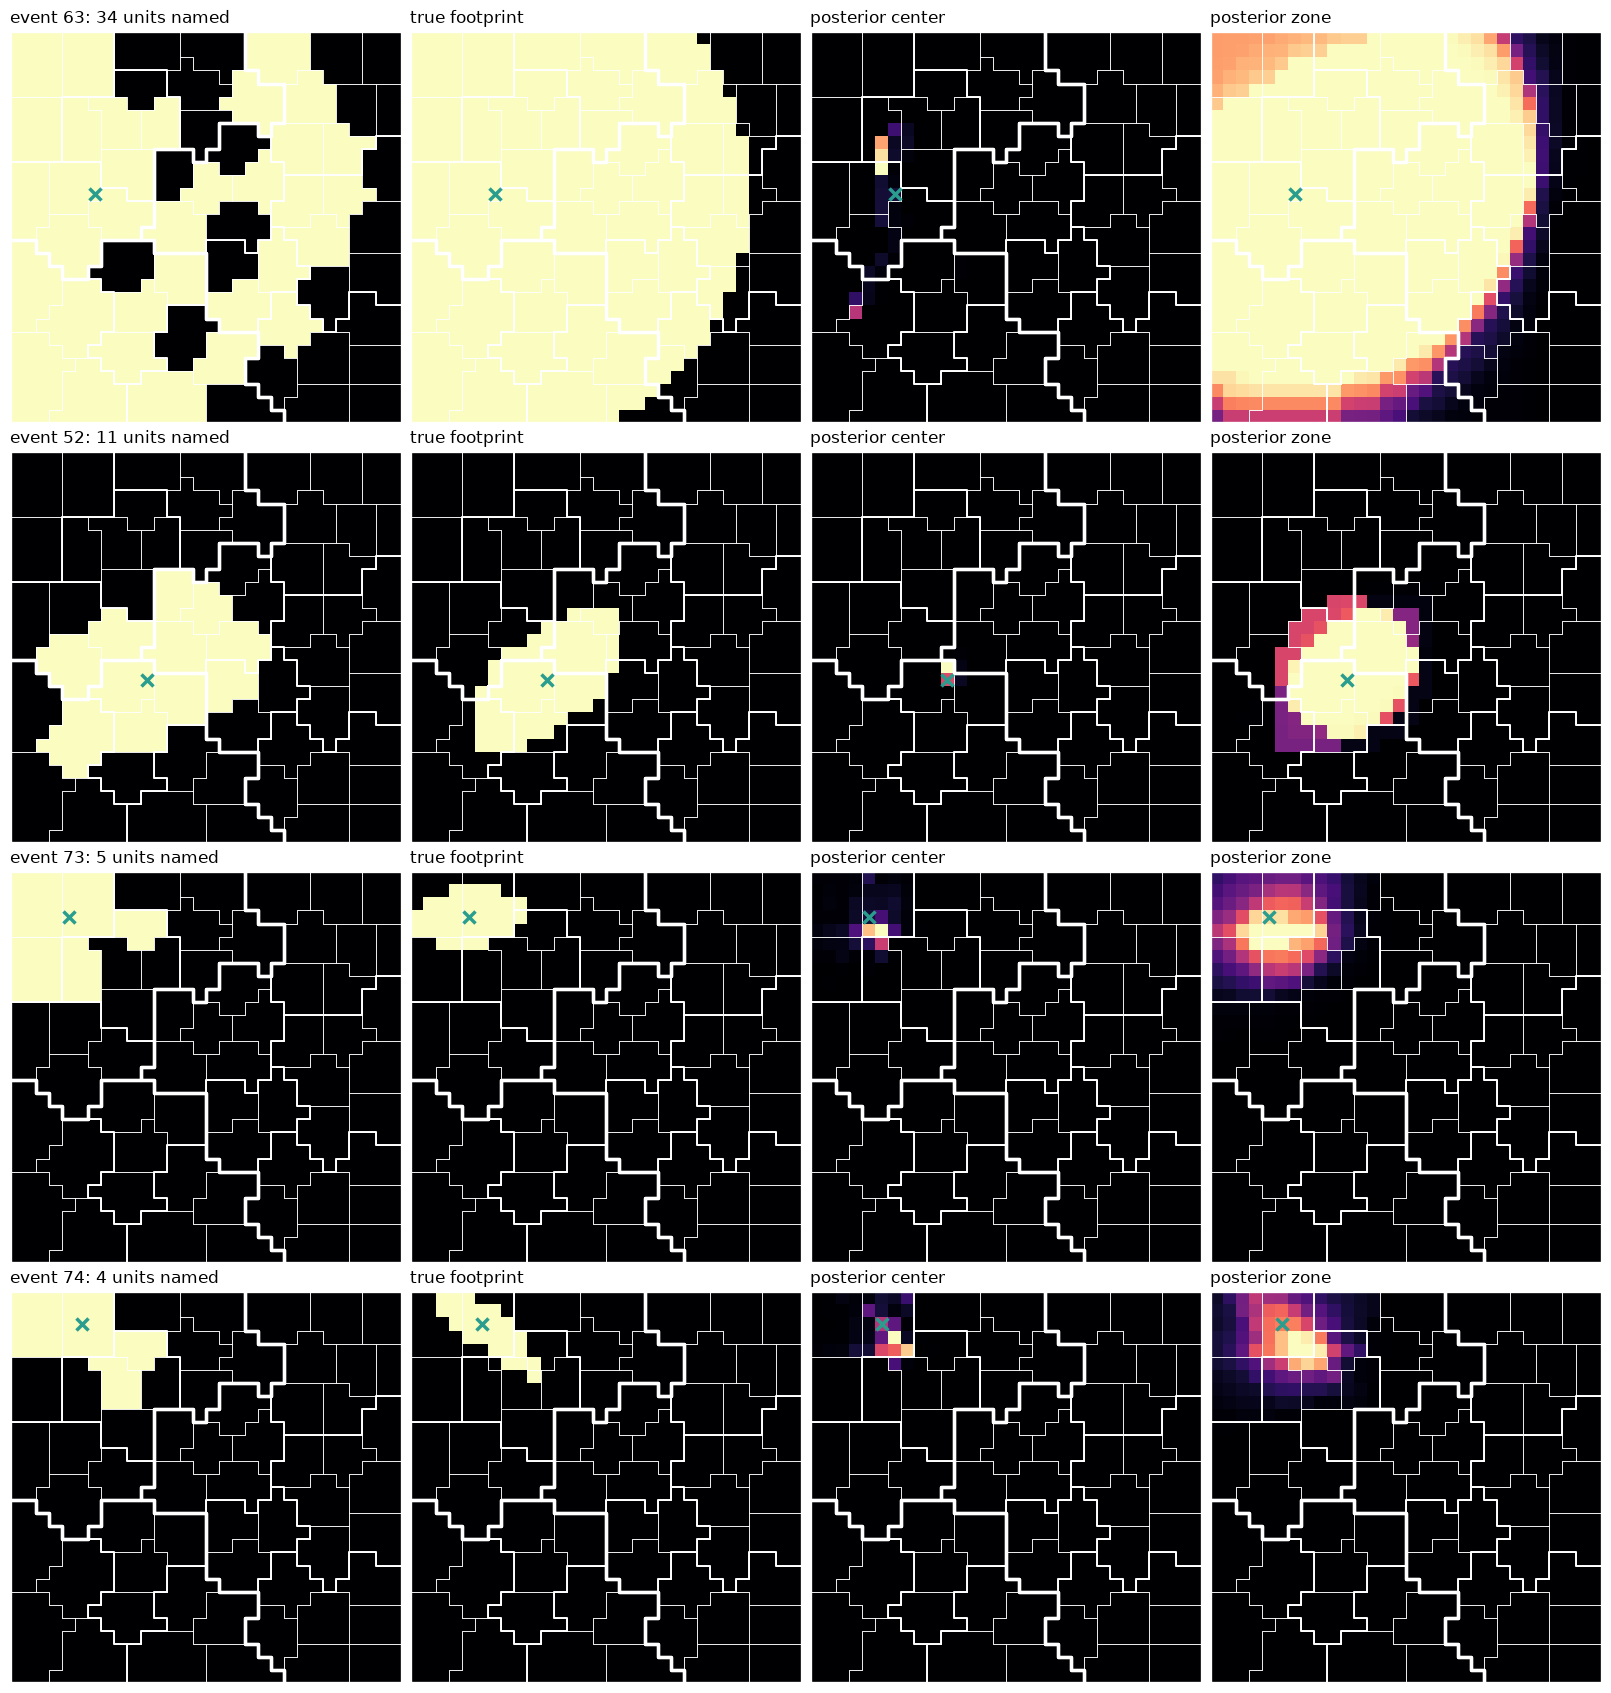

In [19]:
ZONE_KEY = (1, "ADM2")
SHOWN_EVENTS = 4


def unit_mask(level, named):
    """1 on the atoms of the named units, 0 elsewhere."""
    return np.isin(unit_of_atom[level], named).astype(float)


record = records[ZONE_KEY]
# The events naming the most units, where the footprint has the most room to place the center.
shown = np.argsort(record["units named"])[::-1][:SHOWN_EVENTS]

figure, axes = plt.subplots(SHOWN_EVENTS, 4, figsize=(16, 4.2 * SHOWN_EVENTS))
for row_axes, event in zip(axes, shown, strict=True):
    center_map, zone = recover_event(ZONE_KEY, event, recovery_draws[ZONE_KEY])
    true_center = record["centers"][event]
    panels = {
        f"event {event}: {record['units named'][event]} units named": unit_mask(record["levels"][event], record["named"][event]),
        "true footprint": record["insides"][event].astype(float),
        "posterior center": center_map,
        "posterior zone": zone,
    }
    for axis, (title, values) in zip(row_axes, panels.items(), strict=True):
        plot_atoms(axis,
                   values,
                   borders,
                   title=title,
                   vmin=0.0,
                   vmax=values.max())
        axis.plot(atom_x[true_center],
                  atom_y[true_center],
                  "x",
                  color="#2a9d8f",
                  markersize=9,
                  markeredgewidth=2.5)

plt.show()

The events naming the most units are now the tail of a distribution whose median footprint stays inside one unit. Event 63 names 34 units from a footprint covering the western two thirds of the map, one of the few such events in the record, and its zone recovers that extent while its center stays uncertain along a north-south line through the true one. Event 52's true footprint is an ellipse along the diagonal, and its zone is a rounder patch over the 11 named units, with the center placed on the true atom. Events 73 and 74 name 5 and 4 units, and their zones and centers sit on the true ones, slightly rounder and wider than the true ellipses.

## What this establishes

Summing out each event's center and footprint makes the generative story a likelihood that NUTS samples without trouble: its trees are as deep as the event likelihood's. Grouping events by record and pairs by center and missed count leaves the likelihood exact and cuts the largest record from 4.8 million pairs to 196,000 terms, so the footprint fits take six minutes at most. With footprints calibrated to the share of a country real hydrometeorological events name, most stay inside one unit, and the hit rate keeps the center rate's local structure instead of spreading into one blob. The model recovers the median footprint and the naming probability, overstates the spread of footprint sizes, and through that the hit rate's total, by 12% to 87%, while its pattern matches the truth at 0.96 to 0.99. Its center rate matches the event likelihood's. This is one draw of events at one footprint distribution.